In [4]:
import pandas as pd
import os
filename = 'Bicycle_Thefts_Open_Data_3945305316907060423.csv'
data_venkata = pd.read_csv(filename)
print("Column names:")
print(data_venkata.columns.values)


Column names:
['OBJECTID' 'EVENT_UNIQUE_ID' 'PRIMARY_OFFENCE' 'OCC_DATE' 'OCC_YEAR'
 'OCC_MONTH' 'OCC_DOW' 'OCC_DAY' 'OCC_DOY' 'OCC_HOUR' 'REPORT_DATE'
 'REPORT_YEAR' 'REPORT_MONTH' 'REPORT_DOW' 'REPORT_DAY' 'REPORT_DOY'
 'REPORT_HOUR' 'DIVISION' 'LOCATION_TYPE' 'PREMISES_TYPE' 'BIKE_MAKE'
 'BIKE_MODEL' 'BIKE_TYPE' 'BIKE_SPEED' 'BIKE_COLOUR' 'BIKE_COST' 'STATUS'
 'HOOD_158' 'NEIGHBOURHOOD_158' 'HOOD_140' 'NEIGHBOURHOOD_140'
 'LONG_WGS84' 'LAT_WGS84' 'x' 'y']


In [8]:
print("Data types of each column")
print(data_venkata.dtypes)


Data types of each column
OBJECTID               int64
EVENT_UNIQUE_ID       object
PRIMARY_OFFENCE       object
OCC_DATE              object
OCC_YEAR               int64
OCC_MONTH             object
OCC_DOW               object
OCC_DAY                int64
OCC_DOY                int64
OCC_HOUR               int64
REPORT_DATE           object
REPORT_YEAR            int64
REPORT_MONTH          object
REPORT_DOW            object
REPORT_DAY             int64
REPORT_DOY             int64
REPORT_HOUR            int64
DIVISION              object
LOCATION_TYPE         object
PREMISES_TYPE         object
BIKE_MAKE             object
BIKE_MODEL            object
BIKE_TYPE             object
BIKE_SPEED           float64
BIKE_COLOUR           object
BIKE_COST            float64
STATUS                object
HOOD_158              object
NEIGHBOURHOOD_158     object
HOOD_140              object
NEIGHBOURHOOD_140     object
LONG_WGS84           float64
LAT_WGS84            float64
x                

In [5]:
print("Data Set Size:")
print(data_venkata.shape)
#There are 39,473 recorded bike thefts with 35 different pieces of information of each theft

Count of records:
(39473, 35)


In [9]:
print("Top 5 Records:")
print(data_venkata.head(5))

Top 5 Records:
   OBJECTID EVENT_UNIQUE_ID   PRIMARY_OFFENCE               OCC_DATE  \
0         1  GO-20141263544               B&E  12/26/2013 5:00:00 AM   
1         2  GO-20141263784  PROPERTY - FOUND    1/1/2014 5:00:00 AM   
2         3  GO-20141261431       THEFT UNDER    1/1/2014 5:00:00 AM   
3         4  GO-20149000090       THEFT UNDER    1/1/2014 5:00:00 AM   
4         5  GO-20141267465       THEFT UNDER   9/30/2013 4:00:00 AM   

   OCC_YEAR  OCC_MONTH    OCC_DOW  OCC_DAY  OCC_DOY  OCC_HOUR  ... BIKE_COST  \
0      2013   December   Thursday       26      360        19  ...    1300.0   
1      2014    January  Wednesday        1        1        18  ...       NaN   
2      2014    January  Wednesday        1        1         7  ...       NaN   
3      2014    January  Wednesday        1        1        12  ...    1019.0   
4      2013  September     Monday       30      273         0  ...     750.0   

      STATUS HOOD_158             NEIGHBOURHOOD_158  HOOD_140  \
0     

In [12]:
print(" Unique values in each column:")
for col in data_venkata.columns:
    print(f"{col}: {data_venkata[col].unique()}")

 Unique values in each column:
OBJECTID: [    1     2     3 ... 39471 39472 39473]
EVENT_UNIQUE_ID: ['GO-20141263544' 'GO-20141263784' 'GO-20141261431' ... 'GO-20252055843'
 'GO-20252055001' 'GO-20252059600']
PRIMARY_OFFENCE: ['B&E' 'PROPERTY - FOUND' 'THEFT UNDER' 'THEFT FROM MOTOR VEHICLE UNDER'
 'PROPERTY - LOST' 'THEFT UNDER - BICYCLE' "B&E W'INTENT" 'MISCHIEF UNDER'
 'POSSESSION PROPERTY OBC UNDER' 'THEFT OVER' 'INCIDENT - BICYCLE'
 'FRAUD UNDER' 'THEFT UNDER - SHOPLIFTING' 'FTC PROBATION ORDER'
 'INCIDENT' 'PROPERTY - RECOVERED' 'ROBBERY - MUGGING'
 'CARELESS DRIVING- HTA' 'ROBBERY WITH WEAPON' 'ROBBERY - OTHER'
 'THEFT OF MOTOR VEHICLE' 'THEFT FROM MOTOR VEHICLE OVER'
 'POSSESSION PROPERTY OBC OVER' 'SUSPICIOUS INCIDENT'
 'UNLAWFULLY IN DWELLING-HOUSE' 'FRAUD OVER' 'INTIMATE PARTNER INCIDENT'
 'MISCHIEF - ENDANGER LIFE' 'MISCHIEF - INTERFERE W-PROP'
 'ROBBERY - SWARMING' 'AGGRAVATED ASLT PEACE OFFICER' 'ASSAULT'
 'ASSAULT WITH WEAPON' 'ROBBERY - HOME INVASION'
 'ARR/WARR EXECUTE

In [10]:
print("Statistical summary (Mean, Std ,min, max):")
print(data_venkata.describe())


Statistical summary (Mean, Std ,min, max):
           OBJECTID      OCC_YEAR       OCC_DAY       OCC_DOY      OCC_HOUR  \
count  39473.000000  39473.000000  39473.000000  39473.000000  39473.000000   
mean   19737.000000   2019.067616     15.659539    200.162288     13.301143   
std    11395.017925      3.231275      8.638106     77.765684      6.514874   
min        1.000000   1975.000000      1.000000      1.000000      0.000000   
25%     9869.000000   2016.000000      8.000000    149.000000      9.000000   
50%    19737.000000   2019.000000     16.000000    203.000000     14.000000   
75%    29605.000000   2022.000000     23.000000    257.000000     18.000000   
max    39473.000000   2025.000000     31.000000    366.000000     23.000000   

        REPORT_YEAR    REPORT_DAY    REPORT_DOY   REPORT_HOUR    BIKE_SPEED  \
count  39473.000000  39473.000000  39473.000000  39473.000000  37917.000000   
mean    2019.090948     15.992704    201.244142     14.295924     14.110847   
std     

In [28]:
import numpy as np
import pandas as pd

df = data_venkata.copy()
df = df[df['BIKE_COST'] > 0]                          # remove 0 and negative
df = df[df['BIKE_COST'] < 20000]                      # remove crazy outliers
df['RECOVERED'] = (df['STATUS'] == 'RECOVERED').astype(int)


def corrcoeff(d, x, y):
    mx = d[x].mean()
    my = d[y].mean()
    num = ((d[x] - mx) * (d[y] - my)).sum()
    den = np.sqrt(((d[x] - mx)**2).sum() * ((d[y] - my)**2).sum())
    return num / den


print("Correlation BIKE_COST ↔ RECOVERED :", corrcoeff(df, 'BIKE_COST', 'RECOVERED'))
#negatively correlated , no statistical evidence tht bike cost is related to recovery

Correlation BIKE_COST ↔ RECOVERED : 0.011959706023238962


In [29]:
import numpy as np
import pandas as pd

# Create a binary column: 1 if stolen from Apartment/Condo, 0 otherwise
df = data_venkata.copy()
df['IS_APARTMENT'] = (df['PREMISES_TYPE'] == 'Apartment').astype(int)

# Total thefts from apartments vs everywhere else
print("Thefts from Apartments :", df['IS_APARTMENT'].sum())
print("Thefts from elsewhere :", len(df) - df['IS_APARTMENT'].sum())
print("Percentage in Apartments :", round(df['IS_APARTMENT'].mean()*100, 1), "%")



Thefts from Apartments : 9668
Thefts from elsewhere : 29805
Percentage in Apartments : 24.5 %


In [30]:
import pandas as pd
data_venkata.isna().sum()
print("missing values in the dataset columns")

OBJECTID                 0
EVENT_UNIQUE_ID          0
PRIMARY_OFFENCE          0
OCC_DATE                 0
OCC_YEAR                 0
OCC_MONTH                0
OCC_DOW                  0
OCC_DAY                  0
OCC_DOY                  0
OCC_HOUR                 0
REPORT_DATE              0
REPORT_YEAR              0
REPORT_MONTH             0
REPORT_DOW               0
REPORT_DAY               0
REPORT_DOY               0
REPORT_HOUR              0
DIVISION                 0
LOCATION_TYPE            0
PREMISES_TYPE            0
BIKE_MAKE              188
BIKE_MODEL           14913
BIKE_TYPE                0
BIKE_SPEED            1556
BIKE_COLOUR           3521
BIKE_COST             2604
STATUS                   0
HOOD_158                 0
NEIGHBOURHOOD_158        0
HOOD_140                 0
NEIGHBOURHOOD_140        0
LONG_WGS84               0
LAT_WGS84                0
x                        0
y                        0
dtype: int64

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Quick date columns 
data_venkata['OCC_DATE'] = pd.to_datetime(data_venkata['OCC_DATE'])
data_venkata['YEAR']  = data_venkata['OCC_DATE'].dt.year
data_venkata['MONTH'] = data_venkata['OCC_DATE'].dt.month
data_venkata['HOUR']  = data_venkata['OCC_DATE'].dt.hour
data_venkata['DOW']   = data_venkata['OCC_DATE'].dt.day_name()




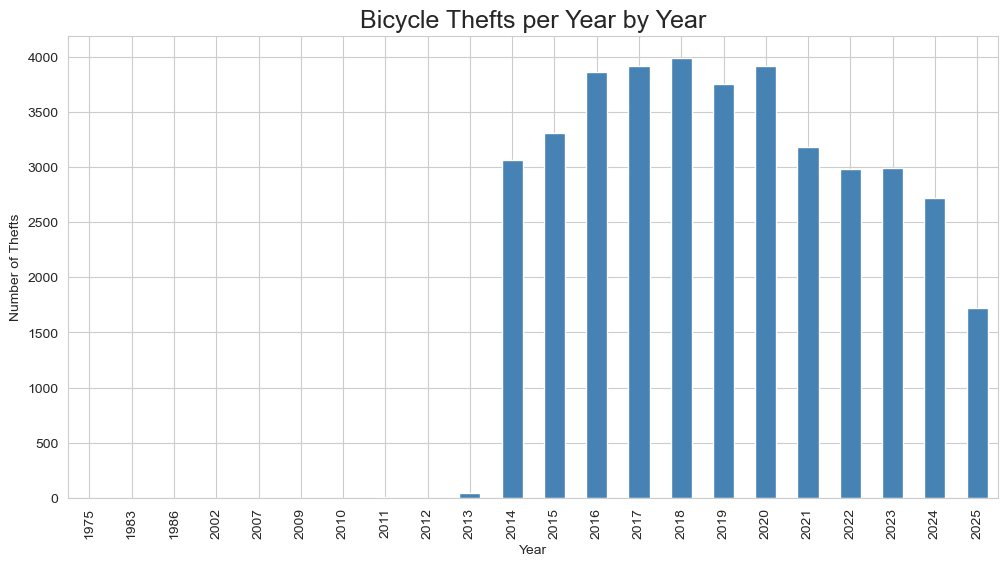

In [34]:
sns.set_style("whitegrid")
plt.figure(figsize=(12,6))

# 1. Thefts per year
data_venkata['YEAR'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Bicycle Thefts per Year by Year', fontsize=18)
plt.ylabel('Number of Thefts')
plt.xlabel('Year')
plt.show()

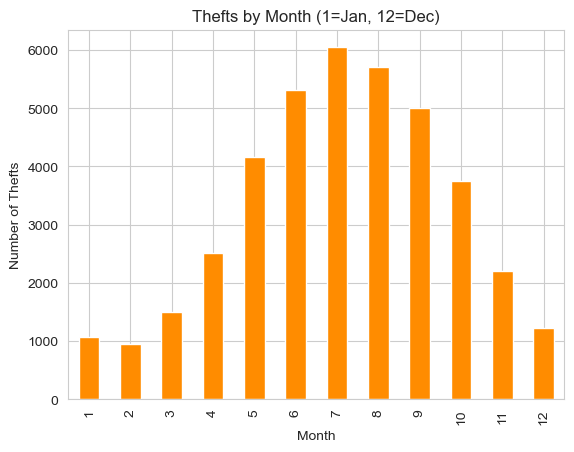

In [35]:
# 2. Thefts by month (all years together)
data_venkata['MONTH'].value_counts().sort_index().plot(kind='bar', color='darkorange')
plt.title('Thefts by Month (1=Jan, 12=Dec)')
plt.ylabel('Number of Thefts')
plt.xlabel('Month')
plt.show()

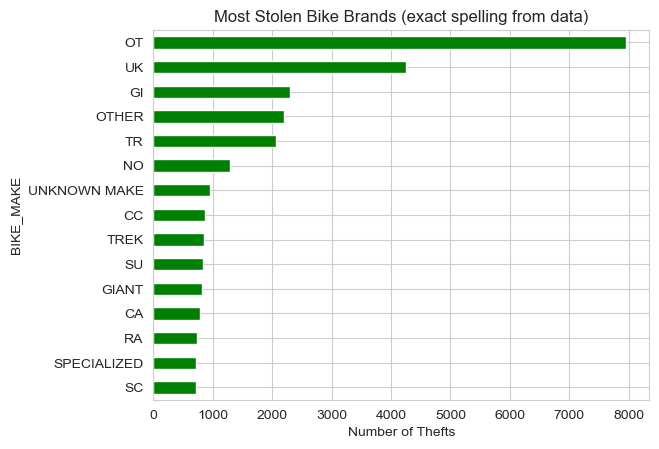

In [36]:
# 3. Top 15 bike brands exactly as written in the file
data_venkata['BIKE_MAKE'].value_counts().head(15).plot(kind='barh', color='green')
plt.title('Most Stolen Bike Brands (exact spelling from data)')
plt.xlabel('Number of Thefts')
plt.gca().invert_yaxis()
plt.show()

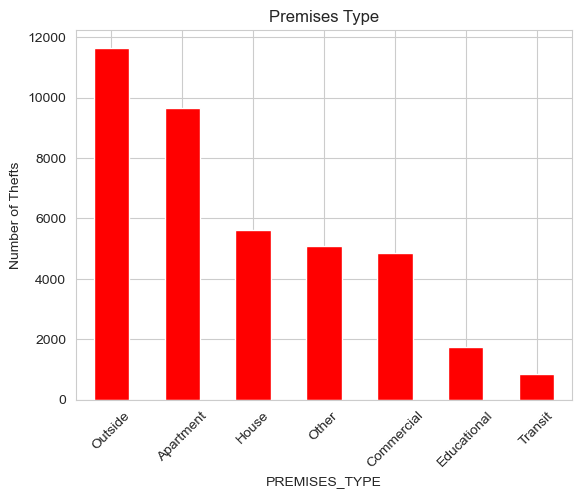

In [37]:
# 4. Where the bikes are stolen from
df['PREMISES_TYPE'].value_counts().plot(kind='bar', color='red')
plt.title('Premises Type')
plt.ylabel('Number of Thefts')
plt.xticks(rotation=45)
plt.show()

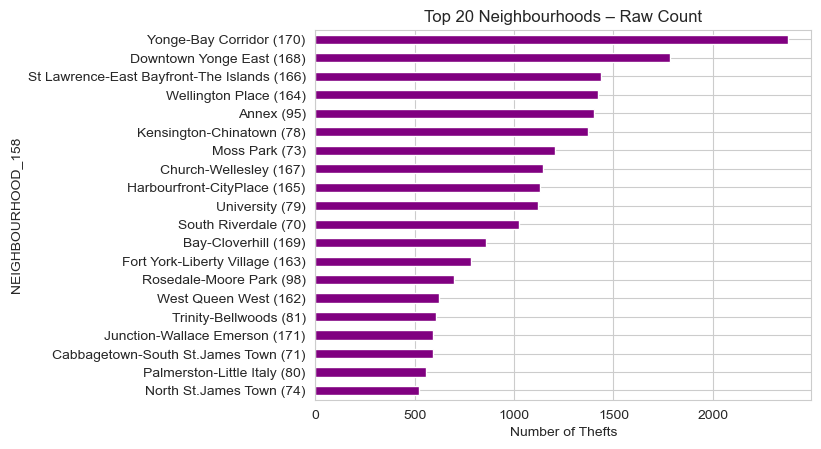

In [38]:
# 5. Top 20 neighbourhoods (158 system – the new one)
df['NEIGHBOURHOOD_158'].value_counts().head(20).plot(kind='barh', color='purple')
plt.title('Top 20 Neighbourhoods – Raw Count')
plt.xlabel('Number of Thefts')
plt.gca().invert_yaxis()
plt.show()

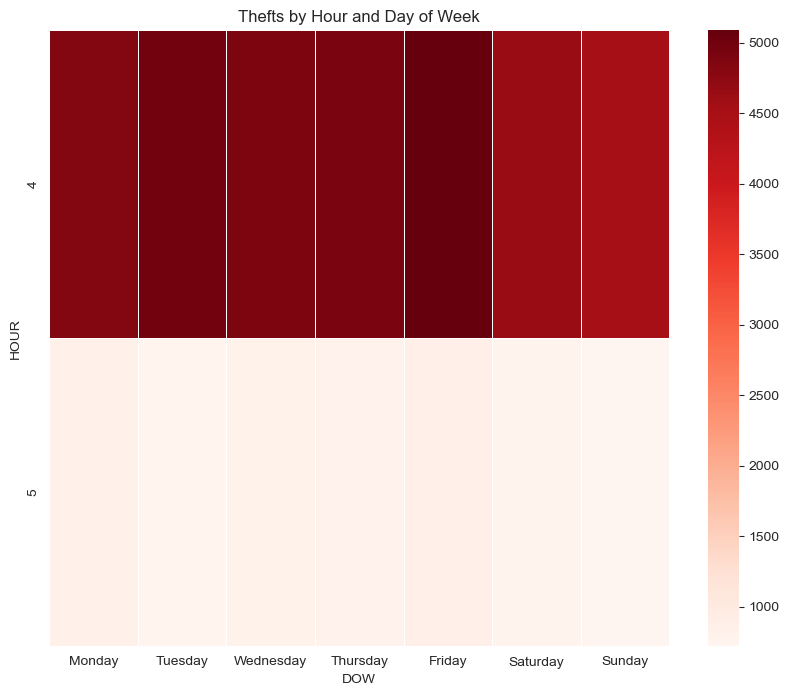

In [40]:
# 6. Heatmap: Hour vs Day of Week
pivot = data_venkata.pivot_table(values='OBJECTID', index='HOUR', columns='DOW',
                       aggfunc='count', fill_value=0)
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = pivot[order]
plt.figure(figsize=(10,8))
sns.heatmap(pivot, cmap="Reds", linewidths=.5)
plt.title('Thefts by Hour and Day of Week')
plt.show()

Text(0, 0.5, 'Number of Bikes Stolen')

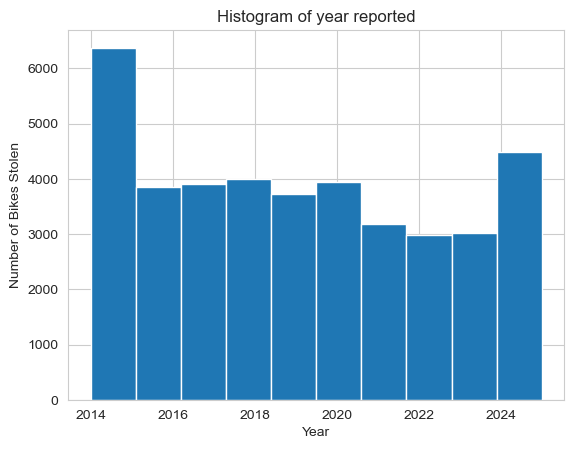

In [44]:
data_venkata.REPORT_YEAR.hist()
plt.title('Histogram of year reported')
plt.xlabel('Year')
plt.ylabel('Number of Bikes Stolen')